In [3]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [4]:
DATA_PATH = "Wine.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("Columns:", list(df.columns))

Dataset shape: (178, 14)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


Columns: ['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline', 'Customer_Segment']


In [9]:
target_col = "Customer_Segment"

X = df.drop(columns=[target_col])
y = df[target_col]

print("Target column:", target_col)
print("Number of features:", X.shape[1])
print("Classes:", sorted(y.unique()))
display(y.value_counts().sort_index().rename_axis("class").to_frame("count"))

Target column: Customer_Segment
Number of features: 13
Classes: [np.int64(1), np.int64(2), np.int64(3)]


,count
class,
1,59
2,71
3,48


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (142, 13)
X_test : (36, 13)


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training means after scaling (approximately 0):")
print(np.round(X_train_scaled.mean(axis=0), 4))
print("Training standard deviations after scaling (approximately 1):")
print(np.round(X_train_scaled.std(axis=0), 4))

Training means after scaling (approximately 0):
[ 0.  0. -0.  0.  0. -0. -0. -0.  0.  0. -0. -0. -0.]
Training standard deviations after scaling (approximately 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
lda = LinearDiscriminantAnalysis(n_components=2)

X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print("X_train_lda shape:", X_train_lda.shape)
print("X_test_lda shape :", X_test_lda.shape)
print("Explained discriminant ratios:", np.round(lda.explained_variance_ratio_, 4))

X_train_lda shape: (142, 2)
X_test_lda shape : (36, 2)
Explained discriminant ratios: [0.6935 0.3065]


In [13]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_lda, y_train)

y_pred = log_reg.predict(X_test_lda)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("=== Confusion Matrix ===")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

=== Classification Report ===
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

=== Confusion Matrix ===
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
Test Accuracy: 0.9722


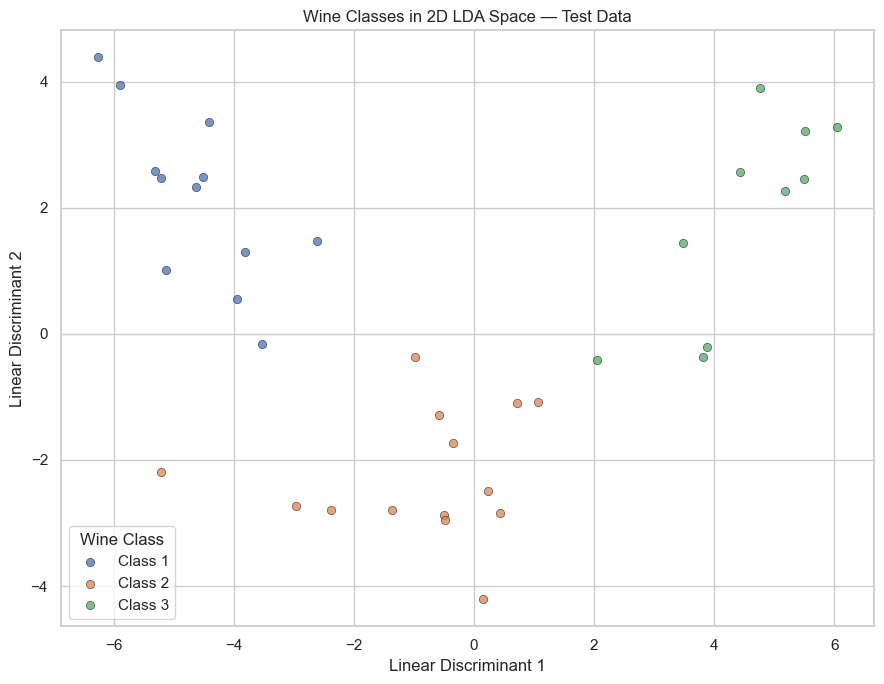

In [14]:
plt.figure(figsize=(9, 7))

for cls in sorted(y_test.unique()):
    mask = y_test.to_numpy() == cls
    plt.scatter(
        X_test_lda[mask, 0],
        X_test_lda[mask, 1],
        label=f"Class {cls}",
        alpha=0.75,
        edgecolor="black",
        linewidth=0.4
    )

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("Wine Classes in 2D LDA Space — Test Data")
plt.legend(title="Wine Class")
plt.tight_layout()
plt.show()